In [ ]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: []


In [ ]:
from datasets import load_dataset
import numpy as np
import matplotlib.pyplot as plt

dataset = load_dataset("Layered-Labs/ACNE04")

data = dataset["train"]

print("Jumlah data:", len(data))
print("Kolom dataset:", data.column_names)


Jumlah data: 1457
Kolom dataset: ['image', 'file_name', 'level', 'severity', 'lesion_count_label', 'num_lesions_annotated', 'lesion_boxes', 'split', 'fold_0_split', 'fold_1_split', 'fold_2_split', 'fold_3_split', 'fold_4_split']


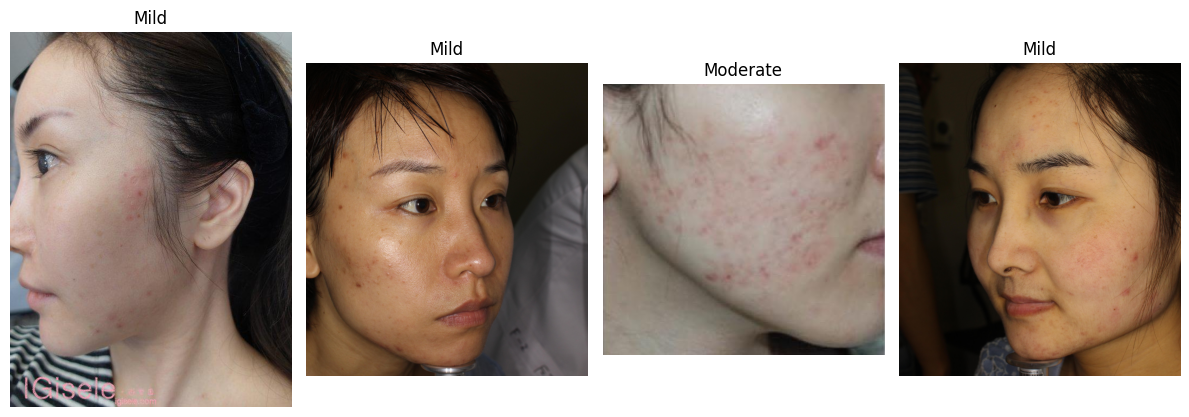

In [ ]:
nama_kelas = ["Mild", "Moderate", "Severe", "Very Severe"]

plt.figure(figsize=(12, 6))

for i in range(4):
    gambar = data[i]["image"]
    label = data[i]["level"]

    plt.subplot(1, 4, i + 1)
    plt.imshow(gambar)
    plt.title(nama_kelas[label])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

# Mengambil kolom split dan level saja
split = np.array(data["split"])
level = np.array(data["level"])

# Mencari indeks train dan test resmi
idx_train_asli = np.where(split == "train")[0]
idx_test = np.where(split == "test")[0]

# Membagi indeks train menjadi train dan validation
idx_train, idx_val = train_test_split(
    idx_train_asli,
    test_size=0.2,
    random_state=42,
    stratify=level[idx_train_asli]
)

# Mengambil data menggunakan indeks
data_train = data.select(idx_train.tolist())
data_val = data.select(idx_val.tolist())
data_test = data.select(idx_test.tolist())

# Menampilkan jumlah data
print("Training  :", len(data_train))
print("Validation:", len(data_val))
print("Testing   :", len(data_test))

Training  : 932
Validation: 233
Testing   : 292


In [ ]:
from skimage.feature import hog, local_binary_pattern

UKURAN_GAMBAR = (128, 128)

P = 8  # Jumlah titik tetangga LBP
R = 1  # Radius LBP

def ekstrak_fitur(gambar):

    # Step 1: Preprocessing
    gambar = gambar.convert("RGB").resize(UKURAN_GAMBAR)
    gray = np.asarray(gambar.convert("L"), dtype=np.uint8)

    # Step 2: Ekstraksi fitur HOG
    fitur_hog = hog(
        gray,
        orientations=9,
        pixels_per_cell=(16, 16),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        feature_vector=True
    ).astype(np.float32)

    # Step 3: Ekstraksi fitur LBP
    peta_lbp = local_binary_pattern(
        gray,
        P=P,
        R=R,
        method="uniform"
    )

    # Step 4: Histogram LBP pada 16 area gambar
    fitur_lbp = []

    for baris in range(0, 128, 32):
        for kolom in range(0, 128, 32):

            bagian = peta_lbp[
                baris:baris + 32,
                kolom:kolom + 32
            ]

            histogram, _ = np.histogram(
                bagian.ravel(),
                bins=np.arange(0, P + 3)
            )

            histogram = histogram.astype(np.float32)
            histogram = histogram / (histogram.sum() + 1e-8)

            fitur_lbp.extend(histogram)

    fitur_lbp = np.asarray(fitur_lbp, dtype=np.float32)

    # Step 5: Gabungkan fitur HOG dan LBP
    fitur_gabungan = np.concatenate((
        fitur_hog,
        fitur_lbp
    ))

    return fitur_gabungan


# Mencoba pada satu gambar
contoh = ekstrak_fitur(data_train[0]["image"])

print("Jumlah fitur:", len(contoh))

Jumlah fitur: 1924


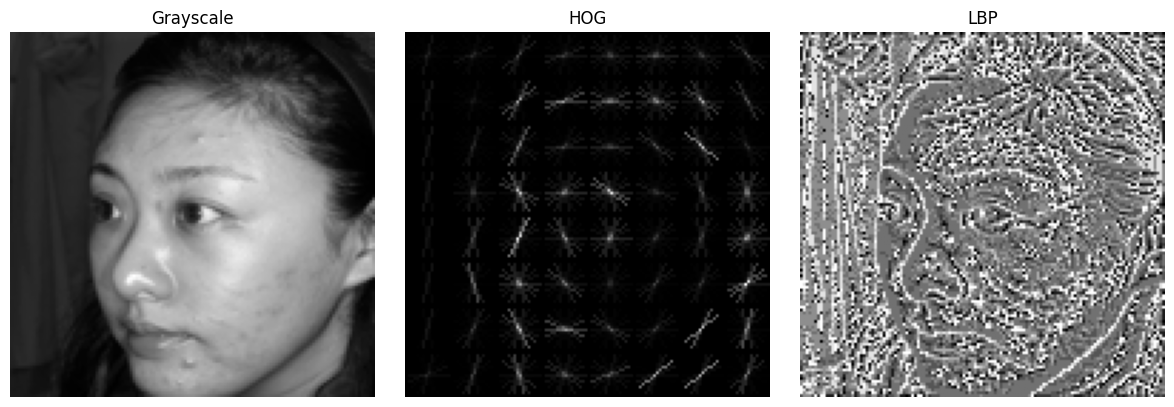

In [ ]:
gambar = data_train[0]["image"].convert("RGB")
gambar = gambar.resize(UKURAN_GAMBAR)

gray = np.asarray(gambar.convert("L"), dtype=np.uint8)

# HOG
_, visual_hog = hog(
    gray,
    orientations=9,
    pixels_per_cell=(16, 16),
    cells_per_block=(2, 2),
    visualize=True
)

# LBP
visual_lbp = local_binary_pattern(
    gray,
    P=P,
    R=R,
    method="uniform"
)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(visual_hog, cmap="gray")
plt.title("HOG")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(visual_lbp, cmap="gray")
plt.title("LBP")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from tqdm.auto import tqdm

def buat_matriks_fitur(data_gambar):

    semua_fitur = []

    for baris in tqdm(data_gambar, total=len(data_gambar)):
        fitur = ekstrak_fitur(baris["image"])
        semua_fitur.append(fitur)

    return np.asarray(semua_fitur, dtype=np.float32)


# Ekstraksi masing-masing data
X_train = buat_matriks_fitur(data_train)
X_val = buat_matriks_fitur(data_val)
X_test = buat_matriks_fitur(data_test)

# Mengambil target severity
y_train = np.asarray(data_train["level"], dtype=int)
y_val = np.asarray(data_val["level"], dtype=int)
y_test = np.asarray(data_test["level"], dtype=int)

# Melihat bentuk data
print("X_train:", X_train.shape)
print("X_val  :", X_val.shape)
print("X_test :", X_test.shape)

  0%|          | 0/932 [00:00<?, ?it/s]

  0%|          | 0/233 [00:00<?, ?it/s]

  0%|          | 0/292 [00:00<?, ?it/s]

X_train: (932, 1924)
X_val  : (233, 1924)
X_test : (292, 1924)


In [ ]:
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import f1_score

# Konfigurasi SVM yang akan dicoba
konfigurasi = [
    {"kernel": "linear", "C": 0.1},
    {"kernel": "linear", "C": 1.0},
    {"kernel": "rbf", "C": 1.0},
    {"kernel": "rbf", "C": 10.0}
]

hasil_validasi = []
konfigurasi_terbaik = None
skor_terbaik = -1

for konfigurasi_model in konfigurasi:

    # Membuat pipeline scaling + SVM
    model = make_pipeline(
        StandardScaler(),
        SVC(
            kernel=konfigurasi_model["kernel"],
            C=konfigurasi_model["C"],
            gamma="scale",
            class_weight="balanced"
        )
    )

    # Training
    model.fit(X_train, y_train)

    # Prediksi validation
    pred_val = model.predict(X_val)

    # Evaluasi
    skor = f1_score(
        y_val,
        pred_val,
        labels=[0, 1, 2, 3],
        average="macro",
        zero_division=0
    )

    hasil_validasi.append({
        "kernel": konfigurasi_model["kernel"],
        "C": konfigurasi_model["C"],
        "macro_f1": skor
    })

    # Menyimpan konfigurasi terbaik
    if skor > skor_terbaik:
        skor_terbaik = skor
        konfigurasi_terbaik = konfigurasi_model.copy()


print(pd.DataFrame(hasil_validasi).sort_values(
    "macro_f1",
    ascending=False
))

print("Parameter terbaik:", konfigurasi_terbaik)
print("Macro F1 terbaik:", round(skor_terbaik, 4))

   kernel     C  macro_f1
3     rbf  10.0  0.496480
0  linear   0.1  0.471100
1  linear   1.0  0.468483
2     rbf   1.0  0.454762
Parameter terbaik: {'kernel': 'rbf', 'C': 10.0}
Macro F1 terbaik: 0.4965


Accuracy: 0.5787671232876712
Macro F1: 0.5108451138306693
MAE Severity: 0.4931506849315068

Classification Report:

              precision    recall  f1-score   support

        Mild       0.65      0.50      0.57       103
    Moderate       0.56      0.75      0.64       127
      Severe       0.46      0.17      0.24        36
 Very Severe       0.57      0.62      0.59        26

    accuracy                           0.58       292
   macro avg       0.56      0.51      0.51       292
weighted avg       0.58      0.58      0.56       292



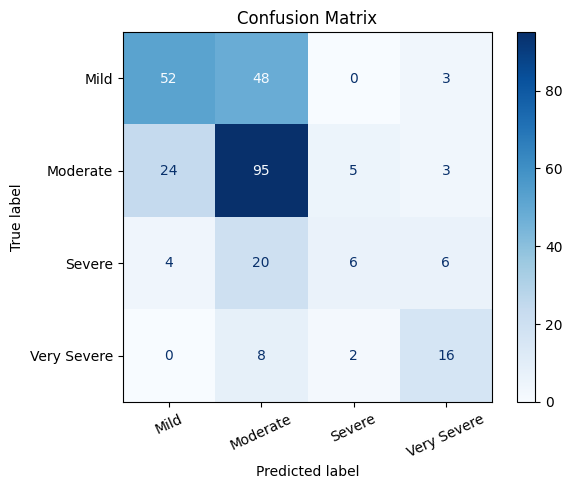

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    mean_absolute_error
)

# Gabungkan training dan validation
X_train_semua = np.vstack((X_train, X_val))
y_train_semua = np.concatenate((y_train, y_val))

# Buat model final
model_final = make_pipeline(
    StandardScaler(),
    SVC(
        kernel=konfigurasi_terbaik["kernel"],
        C=konfigurasi_terbaik["C"],
        gamma="scale",
        class_weight="balanced"
    )
)

# Training ulang
model_final.fit(X_train_semua, y_train_semua)

# Prediksi data testing
pred_test = model_final.predict(X_test)

# Evaluasi
print("Accuracy:", accuracy_score(y_test, pred_test))

print("Macro F1:", f1_score(
    y_test, pred_test, average="macro"
))

print("MAE Severity:", mean_absolute_error(
    y_test, pred_test
))

print("\nClassification Report:\n")

print(classification_report(
    y_test,
    pred_test,
    labels=[0, 1, 2, 3],
    target_names=nama_kelas,
    zero_division=0
))

# Confusion Matrix
cm = confusion_matrix(
    y_test,
    pred_test,
    labels=[0, 1, 2, 3]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=nama_kelas
)

disp.plot(cmap="Blues", values_format="d")
plt.xticks(rotation=25)
plt.title("Confusion Matrix")
plt.show()

In [ ]:
from google.colab import files
from PIL import Image
import io

# Upload gambar
unggahan = files.upload()

nama_file = next(iter(unggahan))
gambar_baru = Image.open(
    io.BytesIO(unggahan[nama_file])
)

# Ekstraksi fitur (sama seperti training)
fitur_baru = ekstrak_fitur(gambar_baru)

# Menjadi input berbentuk 1 baris
fitur_baru = fitur_baru.reshape(1, -1)

# Prediksi dengan SVM
prediksi = int(model_final.predict(fitur_baru)[0])

# Menampilkan gambar dan hasil
plt.imshow(gambar_baru)
plt.axis("off")
plt.title("Prediksi: " + nama_kelas[prediksi])
plt.show()

print("Hasil prediksi:", nama_kelas[prediksi])

StopIteration: 